In [30]:
%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd

# Importación desde el paquete modular refactorizado
from datascience_toolkit import (
    EDAQuick,
    EDAAdvanced,
    SupervisedRegression,   # Alias de RegressionTournament
    DFPreprocess,
)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [31]:
df = pd.read_csv("../data/BostonCasas.csv")

In [32]:
df.head(3)

,Unnamed: 0,Crimin,ResidM25,NegocMin,LimitaRC,OxNitr,Habitac,VivA1940,Distanc,AccAutop,Impuesto,AlumProf,Afroame,ClaseBaja,ValorProm
0,1,0.00632,18.0,Baja,No,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,2,0.02731,0.0,Baja,No,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,3,0.02729,0.0,Baja,No,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7


In [33]:
df.drop(columns=["Unnamed: 0"], inplace=True)

In [34]:
df.head(3)

,Crimin,ResidM25,NegocMin,LimitaRC,OxNitr,Habitac,VivA1940,Distanc,AccAutop,Impuesto,AlumProf,Afroame,ClaseBaja,ValorProm
0,0.00632,18.0,Baja,No,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,Baja,No,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,Baja,No,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7


In [35]:
eda = EDAQuick(df, target="ValorProm")
eda.run_eda()

Columnas convertidas a category: ['NegocMin', 'LimitaRC']
========== DATASET INFO ==========
rows: 506
cols: 14
memory_mb: 0.05
duplicates_rows: 0
target: ValorProm
n_numeric: 12
n_categorical: 2
n_datetime: 0
n_boolean: 0
n_other: 0

========== SUMMARY (top) ==========


,dtype,n_null,pct_null,n_unique,pct_unique
Crimin,float64,0,0.0000,504,99.6047
ClaseBaja,float64,0,0.0000,455,89.9209
Habitac,float64,0,0.0000,446,88.1423
Distanc,float64,0,0.0000,412,81.4229
Afroame,float64,0,0.0000,357,70.5534
VivA1940,float64,0,0.0000,356,70.3557
ValorProm,float64,0,0.0000,229,45.2569
OxNitr,float64,0,0.0000,81,16.0079
Impuesto,int64,0,0.0000,66,13.0435
AlumProf,float64,0,0.0000,46,9.0909



========== DESCRIBE (numeric) ==========


,count,mean,std,min,25%,50%,75%,max
Crimin,506.0000,3.6135,8.6015,0.0063,0.0820,0.2565,3.6771,88.9762
ResidM25,506.0000,11.3636,23.3225,0.0000,0.0000,0.0000,12.5000,100.0000
OxNitr,506.0000,0.5547,0.1159,0.3850,0.4490,0.5380,0.6240,0.8710
Habitac,506.0000,6.2846,0.7026,3.5610,5.8855,6.2085,6.6235,8.7800
VivA1940,506.0000,68.5749,28.1489,2.9000,45.0250,77.5000,94.0750,100.0000
Distanc,506.0000,3.7950,2.1057,1.1296,2.1002,3.2074,5.1884,12.1265
AccAutop,506.0000,9.5494,8.7073,1.0000,4.0000,5.0000,24.0000,24.0000
Impuesto,506.0000,408.2372,168.5371,187.0000,279.0000,330.0000,666.0000,711.0000
AlumProf,506.0000,18.4555,2.1649,12.6000,17.4000,19.0500,20.2000,22.0000
Afroame,506.0000,356.6740,91.2949,0.3200,375.3775,391.4400,396.2250,396.9000



========== TARGET DISTRIBUTION ==========


El target no es categórico (o no aplica imbalance).

========== CORRELATION ==========



Pares con |correlación| >= 0.80


,feature_1,feature_2,correlation,abs_correlation
0,AccAutop,Impuesto,0.9102,0.9102



========== OUTLIERS ==========


,feature,n,n_outliers,pct_outliers,lower_bound,upper_bound,min,max
0,Afroame,506,77,15.2174,344.1062,427.4963,0.3200,396.9000
1,ResidM25,506,68,13.4387,-18.7500,31.2500,0.0000,100.0000
2,Crimin,506,66,13.0435,-5.3105,9.0696,0.0063,88.9762
3,ValorProm,506,40,7.9051,5.0625,36.9625,5.0000,50.0000
4,Habitac,506,30,5.9289,4.7785,7.7305,3.5610,8.7800
5,AlumProf,506,15,2.9644,13.2000,24.4000,12.6000,22.0000
6,ClaseBaja,506,7,1.3834,-8.0575,31.9625,1.7300,37.9700
7,Distanc,506,5,0.9881,-2.5322,9.8208,1.1296,12.1265
8,OxNitr,506,0,0.0000,0.1865,0.8865,0.3850,0.8710
9,VivA1940,506,0,0.0000,-28.5500,167.6500,2.9000,100.0000


{'category_conversion': {'converted': ['NegocMin', 'LimitaRC'], 'skipped': []},
 'dataset_info': {'rows': 506,
  'cols': 14,
  'memory_mb': np.float64(0.05),
  'duplicates_rows': 0,
  'target': 'ValorProm',
  'n_numeric': 12,
  'n_categorical': 2,
  'n_datetime': 0,
  'n_boolean': 0,
  'n_other': 0},
 'summary':               dtype  n_null  pct_null  n_unique  pct_unique
 Crimin      float64       0       0.0       504     99.6047
 ClaseBaja   float64       0       0.0       455     89.9209
 Habitac     float64       0       0.0       446     88.1423
 Distanc     float64       0       0.0       412     81.4229
 Afroame     float64       0       0.0       357     70.5534
 VivA1940    float64       0       0.0       356     70.3557
 ValorProm   float64       0       0.0       229     45.2569
 OxNitr      float64       0       0.0        81     16.0079
 Impuesto      int64       0       0.0        66     13.0435
 AlumProf    float64       0       0.0        46      9.0909
 ResidM25    flo

# No se hace advanced porque es para categoricos!

In [36]:

# ==========================================================
# 1. Crear análisis
# ==========================================================

sup = SupervisedRegression(
    df,
    target="ValorProm"
)

# ==========================================================
# 2. Preparación segura
# ==========================================================

sup.prepare(
    test_size=0.20,
    valid_size=0.15,

    scoring="rmse",
    cv_splits=5,

    model_encoding="auto",
    scale_num="standard",
    auto_cardinality_threshold=15
)


sup.add_default_models()


In [37]:

# ==========================================================
# 3. Competencia inicial
# ==========================================================

lb_base = sup.compete(
    metric="rmse"
)

sup.pretty_table(
    lb_base,
    title="Baseline regression competition"
)

Baseline regression competition


,model,metric,cv_mean,cv_std,n_splits,tuned
0,GBR,rmse,3.2954,0.6129,5,False
1,RandomForest,rmse,3.7850,0.6574,5,False
2,Ridge,rmse,5.0079,0.6893,5,False
3,Linear,rmse,5.0616,0.9936,5,False
4,DecisionTree,rmse,5.1554,1.2823,5,False
5,Lasso,rmse,5.5141,0.9892,5,False
6,SVR,rmse,5.7048,1.1354,5,False


In [38]:
# ==========================================================
# 4. HPO rápido sobre los mejores modelos
# ==========================================================

sup.tune_top(
    top=3,
    method="random",
    # "auto"         -> recomendado (elige automáticamente)
    # "random"       -> RandomizedSearchCV
    # "grid"         -> GridSearchCV
    # "bayesian"     -> Optuna (próximamente)
    # "halving"      -> HalvingSearchCV (próximamente)
    # "keras_tuner"  -> únicamente para MLP
    # "none"         -> sin optimización
    n_iter=20
)

# Choose models like this:
#
# sup.tune_models(
#     models=["Ridge", "SVR", "RandomForest", "GBR"],
#     method="random",
#     n_iter=20
# )

✅ GBR: HPO mejoró (3.4833 -> 3.3731)
✅ RandomForest: HPO mejoró (3.6192 -> 3.5037)
✅ Ridge: HPO mejoró (5.2027 -> 5.0978)


{'GBR':     mean_fit_time  std_fit_time  mean_score_time  std_score_time  \
 0        0.710560      0.190984         0.020714        0.012140   
 1        1.740389      0.250536         0.015301        0.002874   
 2        0.618050      0.180712         0.026608        0.009820   
 3        0.281531      0.059790         0.023694        0.008419   
 4        0.662360      0.097699         0.017648        0.003630   
 5        0.302706      0.045964         0.016864        0.004030   
 6        1.033989      0.027719         0.012926        0.000316   
 7        0.985877      0.202854         0.021576        0.015942   
 8        1.314633      0.524039         0.027931        0.010161   
 9        1.030093      0.468857         0.020884        0.007184   
 10       1.755041      0.047761         0.024356        0.003039   
 11       1.365593      0.311089         0.024103        0.009106   
 12       0.578408      0.152367         0.013359        0.004142   
 13       1.196739      0.4

In [39]:

# ==========================================================
# 5. Nueva competencia
# ==========================================================

lb_tuned = sup.compete(
    metric="rmse"
)

sup.pretty_table(
    lb_tuned,
    title="Regression competition after HPO"
)


Regression competition after HPO


,model,metric,cv_mean,cv_std,n_splits,tuned
0,GBR,rmse,3.2795,0.5502,5,True
1,RandomForest,rmse,3.6755,0.6618,5,True
2,Linear,rmse,4.9884,0.6288,5,False
3,Ridge,rmse,4.9960,1.0665,5,True
4,DecisionTree,rmse,5.2502,1.4511,5,False
5,Lasso,rmse,5.5761,0.6441,5,False
6,SVR,rmse,5.6810,1.4948,5,False


In [40]:
# ==========================================================
# 6. Ajustar ganador
# ==========================================================

sup.fit(
    model="best",
    refit_on="train_valid"
)

# ==========================================================
# 7. Evaluar en test
# ==========================================================

test_report = sup.evaluate_test()

sup.pretty_table(
    test_report,
    title="Final regression test metrics"
)

Final regression test metrics


,model,rmse,mae,r2,n_test
0,GBR,3.2017,2.2829,0.8295,102


# LIME

In [41]:
%pip install lime

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [42]:
sup.prepare_lime_explainer(
    background="train",
    max_background=2000,
    discretize_continuous=True,
    discretizer="quartile",
    random_state=42
)

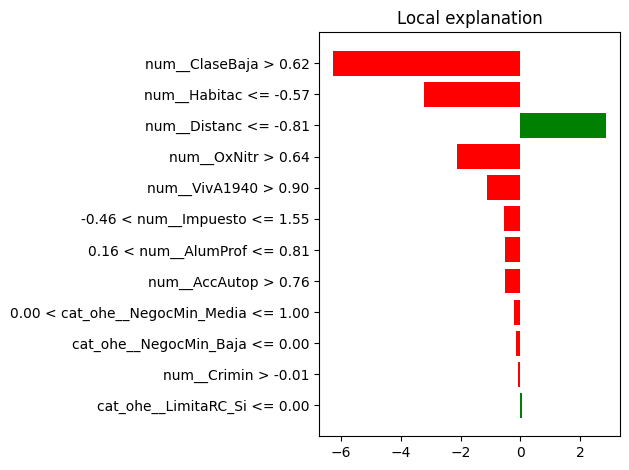

In [43]:
lime_report = sup.explain_instance_lime(
    index=25,
    data="test",
    num_features=12,
    num_samples=5000
)

In [44]:
sup.pretty_table(
    lime_report["explanation"],
    title="LIME explanation — reservation 25"
)

LIME explanation — reservation 25


,rule,lime_weight,abs_weight,direction
0,num__ClaseBaja > 0.62,-6.2742,6.2742,decreases output
1,num__Habitac <= -0.57,-3.2092,3.2092,decreases output
2,num__Distanc <= -0.81,2.8833,2.8833,increases output
3,num__OxNitr > 0.64,-2.1365,2.1365,decreases output
4,num__VivA1940 > 0.90,-1.1135,1.1135,decreases output
5,-0.46 < num__Impuesto <= 1.55,-0.5546,0.5546,decreases output
6,0.16 < num__AlumProf <= 0.81,-0.5247,0.5247,decreases output
7,num__AccAutop > 0.76,-0.5012,0.5012,decreases output
8,0.00 < cat_ohe__NegocMin_Media <= 1.00,-0.2193,0.2193,decreases output
9,cat_ohe__NegocMin_Baja <= 0.00,-0.1506,0.1506,decreases output


In [45]:
print("Class explained:", lime_report["class_label"])
print("Model prediction:", lime_report["model_prediction"])
print("Local prediction:", lime_report["local_prediction"])
print("Local fidelity:", lime_report["local_fidelity"])

Class explained: None
Model prediction: 9.181852288816792
Local prediction: 15.013863144070148
Local fidelity: 0.2859849058820132


In [46]:
sup.lime_summary()

LIME LOCAL EXPLANATION SUMMARY
Model prediction : 9.1819
Local prediction : 15.0139
Local fidelity R²: 0.2860
Reglas locales LIME


,rule,lime_weight,abs_weight,direction
0,num__ClaseBaja > 0.62,-6.2742,6.2742,decreases output
1,num__Habitac <= -0.57,-3.2092,3.2092,decreases output
2,num__Distanc <= -0.81,2.8833,2.8833,increases output
3,num__OxNitr > 0.64,-2.1365,2.1365,decreases output
4,num__VivA1940 > 0.90,-1.1135,1.1135,decreases output
5,-0.46 < num__Impuesto <= 1.55,-0.5546,0.5546,decreases output
6,0.16 < num__AlumProf <= 0.81,-0.5247,0.5247,decreases output
7,num__AccAutop > 0.76,-0.5012,0.5012,decreases output
8,0.00 < cat_ohe__NegocMin_Media <= 1.00,-0.2193,0.2193,decreases output
9,cat_ohe__NegocMin_Baja <= 0.00,-0.1506,0.1506,decreases output


,rule,lime_weight,abs_weight,direction
0,num__ClaseBaja > 0.62,-6.274151,6.274151,decreases output
1,num__Habitac <= -0.57,-3.209245,3.209245,decreases output
2,num__Distanc <= -0.81,2.883271,2.883271,increases output
3,num__OxNitr > 0.64,-2.136464,2.136464,decreases output
4,num__VivA1940 > 0.90,-1.113522,1.113522,decreases output
5,-0.46 < num__Impuesto <= 1.55,-0.554606,0.554606,decreases output
6,0.16 < num__AlumProf <= 0.81,-0.524715,0.524715,decreases output
7,num__AccAutop > 0.76,-0.501211,0.501211,decreases output
8,0.00 < cat_ohe__NegocMin_Media <= 1.00,-0.219345,0.219345,decreases output
9,cat_ohe__NegocMin_Baja <= 0.00,-0.150613,0.150613,decreases output


In [48]:

# ==========================================================
# 8. Revisar distribución del target
# ==========================================================

sup.pretty_table(
    sup.y_distribution_summary(),
    title="Target distribution"
)


Target distribution


,Variable,Min,Q1,Q3,Max,Winner_Model,Metric,Error,Evaluation,strength
0,ValorProm,5.0000,17.0250,25.0000,50.0000,GBR,RMSE,3.2017,Test,Strong


In [28]:
# ==========================================================
# 9. Guardar
# ==========================================================

artifact = sup.save(
    "boston_house_value_model.pkl",
    kind="pickle"
)

print("Saved artifact:", artifact)

Modelo guardado exitosamente en: boston_house_value_model.pkl
Saved artifact: boston_house_value_model.pkl
